# SuperNeuroABM Tutorial 06: How Synaptic Input Reaches a Soma

One model is behind every connection in SuperNeuroABM:

> **A synapse delivers a value into a channel of its post soma. The soma gathers each channel,
> decays it with that channel's time constant, and adds the channels up.**

The two halves run at different times. The synapse acts once per spike: on the tick after its
presynaptic neuron fired it computes a value and drops it into one channel, and is done. The
soma acts on every tick: it reads what arrived in each channel, decays each channel's current,
and integrates the sum.

So there are two places to change how input works, and this tutorial shows one example of each:

1. the model, in the code and on one soma;
2. **a synapse step function** decides *what value* a spike delivers, and into which channel
   (example: a synapse with short-term depression);
3. **a soma step function** decides *what the channels mean* to the soma (example: channels used
   as conductances with reversal potentials instead of currents);
4. which one to write for what you want.

Files used here, next to this notebook:

| file | what it is |
|---|---|
| `customized_configs/synaptic_channels_config.yaml` | every component this notebook creates |
| `customized_step_functions/user_customized_depressing_synapse.py` | section 2: a synapse whose delivered value depresses with use |
| `customized_step_functions/user_customized_conductance_lif.py` | section 3: a LIF soma whose channels are conductances |

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from superneuroabm.model import NeuromorphicModel

CONFIG = Path("customized_configs/synaptic_channels_config.yaml").resolve()
STEP_FUNC_DIR = Path("customized_step_functions").resolve()
sys.path.insert(0, str(STEP_FUNC_DIR))   # the tutorial-owned kernels are imported by module name
from user_customized_depressing_synapse import user_customized_depressing_synapse
from user_customized_conductance_lif import user_customized_conductance_lif

DT = 1e-3                     # the default tick: 1 ms
NO_SPIKES = {"vthr": 1e9}     # threshold out of reach: these somas only show their input


def new_model(stepping="event"):
    return NeuromorphicModel(user_config=CONFIG, synapse_stepping=stepping,
                             enable_internal_states_tracking=True)


def history(model, soma):
    "Per-tick internal-state history of one soma as an array (ticks x columns)."
    return np.array(model.get_internal_states_history(soma), dtype=np.float64)

## 1. The model

### In the code

The built-in synapse, `delivery_synapse` (`superneuroabm/step_functions/synapse/delivery.py`),
reads its presynaptic spike and, if there is one, delivers one value into one channel:

```python
spike = get_soma_spike(...)            # the pre soma's spike of the previous tick (or an injected input)
if spike == 0.0:
    return
weight  = synapse_params[agent_index][0]
scale   = synapse_params[agent_index][2]
channel = int(synapse_params[agent_index][3])
deliver_synaptic_current(synaptic_input, synaptic_input_idx, post_soma_index, channel,
                         spike * scale * weight)
```

`deliver_synaptic_current` adds the value into slot `channel` of the post soma's **inbox**, a
row of `K` numbers per soma. Every synapse that delivers into the same channel of the same
soma on the same tick adds into the same number.

The built-in somas (`lif_soma` and the others) turn their inbox into a current with
`synaptic_current` (`superneuroabm/step_functions/synaptic_input.py`), once per tick:

```python
for c in range(K):
    I_c = I_syn_c * (1 - dt / tau_syn_c) + inbox[c]    # decay channel c, add what arrived
    I_syn_c = I_c                                       # kept in the soma's internal states
    I_total += I_c
```

and integrate `I_total` like any input current. What a synapse delivers on tick `t` is in the
inbox the soma reads on tick `t + 1`; the framework empties the inbox after every tick.

### Who owns which parameter

| | parameters | used |
|---|---|---|
| synapse | `weight`, `scale`, `channel` (and a learning rule, if any) | once per spike, to compute the delivered value |
| soma | `tau_syn_0 ... tau_syn_{K-1}` in its hyperparameters, `I_syn_0 ... I_syn_{K-1}` in its state | every tick, to decay each channel |

`K` is `NeuromorphicModel(synaptic_channels=K)`, default 2, the same for every soma. What a
channel *means* (its time constant) is each soma's own: `tau_syn_c` comes from the soma's config
and can be overridden per soma. A synapse's `channel` is an index into its post soma's channels.

synapse parameters: {'weight': 5.0, 'synaptic_delay': 1.0, 'scale': 1.0, 'channel': 0.0}
soma channel time constants: {'tau_syn_0': 0.009999999776482582, 'tau_syn_1': 0.0020000000949949026}
soma D: {'tau_syn_0': 0.029999999329447746, 'tau_syn_1': 0.0020000000949949026}
A: channel-0 inputs only     max |simulated - closed form| = 5.2e-07
B: channel-1 input only      max |simulated - closed form| = 1.9e-07
C: all three inputs          max |simulated - closed form| = 5.1e-07
D: as A, tau_syn_0 = 30 ms   max |simulated - closed form| = 8.6e-07
C - (A + B): 2.4e-07


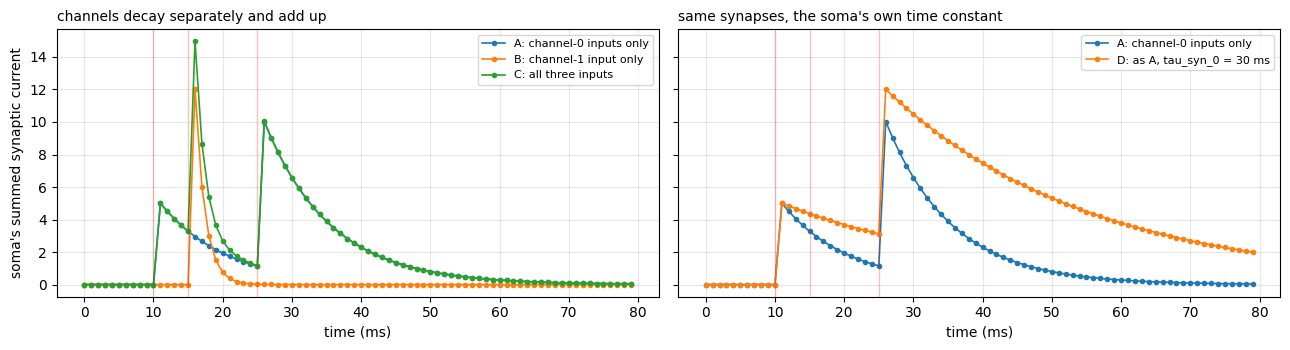

In [2]:
# Three external input synapses (pre_soma_id=-1), each one spike: (channel, weight, tick)
INPUTS = [(0, 5.0, 10), (0, 9.0, 25), (1, 12.0, 15)]
SOMAS = {
    "A: channel-0 inputs only": ([0, 1], {}),
    "B: channel-1 input only": ([2], {}),
    "C: all three inputs": ([0, 1, 2], {}),
    "D: as A, tau_syn_0 = 30 ms": ([0, 1], {"tau_syn_0": 30e-3}),
}
TICKS = 80

model = new_model()
somas, inputs = {}, []
for name, (which, soma_hp) in SOMAS.items():
    somas[name] = model.create_soma(breed="lif_soma", config_name="config_0",
                                    overrides={"hyperparameters": {**NO_SPIKES, **soma_hp}})
    for i in which:
        channel, weight, tick = INPUTS[i]
        syn = model.create_synapse(breed="delivery_synapse", pre_soma_id=-1, post_soma_id=somas[name],
                                   config_name="config_0",
                                   overrides={"hyperparameters": {"weight": weight, "channel": channel}})
        inputs.append((syn, tick))
model.setup()
for syn, tick in inputs:
    model.add_spike(syn, tick, 1.0)
model.simulate(ticks=TICKS)

first_syn = inputs[0][0]
print("synapse parameters:", model.get_hyperparameters(first_syn))
soma_hp = model.get_hyperparameters(somas["A: channel-0 inputs only"])
print("soma channel time constants:", {k: v for k, v in soma_hp.items() if k.startswith("tau_syn")})
print("soma D:", {k: v for k, v in model.get_hyperparameters(somas["D: as A, tau_syn_0 = 30 ms"]).items()
                 if k.startswith("tau_syn")})

# The closed form: each input adds weight * (1 - dt/tau)^n, n ticks after the soma first sees it
ticks = np.arange(TICKS)
def closed_form(which, tau_0):
    I = np.zeros(TICKS)
    for i in which:
        channel, weight, tick = INPUTS[i]
        tau = tau_0 if channel == 0 else soma_hp["tau_syn_1"]
        n = ticks - (tick + 1)
        I += np.where(n >= 0, weight * (1 - DT / tau) ** np.maximum(n, 0), 0.0)
    return I

I_syn = {name: history(model, soma)[:, 3] for name, soma in somas.items()}   # column 3: the summed current
for name, (which, hp) in SOMAS.items():
    err = np.abs(I_syn[name] - closed_form(which, hp.get("tau_syn_0", soma_hp["tau_syn_0"]))).max()
    print(f"{name:28s} max |simulated - closed form| = {err:.1e}")
sum_err = np.abs(I_syn["C: all three inputs"] - I_syn["A: channel-0 inputs only"] - I_syn["B: channel-1 input only"]).max()
print(f"C - (A + B): {sum_err:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
t_ms = ticks * DT * 1e3
for name in ("A: channel-0 inputs only", "B: channel-1 input only", "C: all three inputs"):
    axes[0].plot(t_ms, I_syn[name], marker=".", lw=1.2, label=name)
for name in ("A: channel-0 inputs only", "D: as A, tau_syn_0 = 30 ms"):
    axes[1].plot(t_ms, I_syn[name], marker=".", lw=1.2, label=name)
for ax in axes:
    for _, _, tick in INPUTS:
        ax.axvline(tick * DT * 1e3, color="r", alpha=0.25, lw=1)
    ax.set_xlabel("time (ms)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("soma's summed synaptic current")
axes[0].set_title("channels decay separately and add up", loc="left", fontsize=10)
axes[1].set_title("same synapses, the soma's own time constant", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

What the plots show (the red lines are the input spikes, ticks 10, 15 and 25):

- **Soma A.** Its two synapses use channel 0. The current jumps by 5 the tick after the first
  spike, decays with 10 ms, and jumps by 9 after the second: two synapses on one channel share
  one current. Their weights differ; that needs no second channel, because a weight acts only
  once, when the value is delivered.
- **Soma B.** Its synapse uses channel 1, which this config gives a 2 ms time constant, so the
  same kind of synapse makes a short current.
- **Soma C.** It receives all three and its current is exactly A + B: each channel decays on its
  own and the soma adds them.
- **Soma D.** It receives the same synapses as A, but its own `tau_syn_0` is 30 ms, so the same
  deliveries decay more slowly. The synapse said "channel 0"; the soma decided what channel 0 is.

Every curve matches the closed form `weight * (1 - dt/tau_syn)^n` to float32 rounding.

Two consequences:

- **A soma needs one channel per distinct time constant among its inputs**, not one per synapse.
  Synapses that differ in weight, scale or learning rule share a channel; synapses whose input
  should decay differently need different channels. `K` must cover the soma with the most
  distinct time constants, and the same channel number may mean different time constants on
  different somas.
- **A synapse's `channel` is only checked to be in range** (`0 ... K-1`). If a synapse config is
  pointed at a soma whose channel layout is different, it gets that soma's time constant
  without an error.

The former synapse types are channel settings now (tutorial 02, section 6, shows each):
`weighted_synapse` is a channel with `tau_syn_c = dt` (decay factor 0, a one-tick pulse),
`single_exp_synapse` with `tau_fall` is a channel with `tau_syn_c = tau_fall`, and
`double_exp_synapse` is a custom synapse that delivers into two channels.

## 2. Changing what a spike delivers: a synapse step function

The synapse decides one thing: the value it delivers, and into which channel. To change that,
write a synapse step function: a copy of `delivery_synapse` with a different value computed
before `deliver_synaptic_current`, registered with `register_synapse_type`.

The example is **short-term depression** (the depression part of the Tsodyks-Markram model). The
synapse keeps a fraction `x` of available resources, 1 at rest. Each spike delivers
`weight * U * x` and uses up `U * x` of the resources; between spikes `x` recovers towards 1 with
time constant `tau_rec`. A fast train therefore delivers less and less, and a pause restores it.
The heart of `user_customized_depressing_synapse.py`:

```python
x = internal_states[agent_index][0]
last_tick = internal_states[agent_index][1]
if last_tick >= 0.0:                                   # recover over the ticks since the last spike
    n = t_current - int(last_tick)
    x = 1.0 - (1.0 - x) * trace_decay(dt, tau_rec, n)   # (1 - dt/tau_rec)^n
deliver_synaptic_current(synaptic_input, synaptic_input_idx, post_soma_index, channel,
                         spike * scale * weight * U * x)
internal_states[agent_index][0] = x - U * x            # resources used by this spike
internal_states[agent_index][1] = 1.0 * t_current
```

`x` changes between spikes, but it is only needed when a spike arrives, so the synapse does not
update it every tick: when it is woken it catches up the recovery over the `n` ticks it slept, in
closed form, the way the learning rules catch up their traces. That keeps it event-capable: it
runs only on the tick after its presynaptic neuron fires (`synapse_stepping="event"`, the
default), and gives the same values as when every synapse is stepped every tick. The cell runs
it both ways to check. Nothing on the soma side changes: the delivered value goes into channel 0
of a plain `lif_soma` and decays with that soma's `tau_syn_0`.

delivered by delivery_synapse:   [14. 14. 14. 14. 14. 14. 14. 14. 14. 14.]
delivered by the depressing one: [7.    4.137 2.967 2.488 2.292 2.212 2.179 2.166 6.738 4.03 ]
closed form:                     [7.    4.137 2.967 2.488 2.292 2.212 2.179 2.166 6.738 4.03 ]
event and clocked stepping give the same current, bit for bit: True


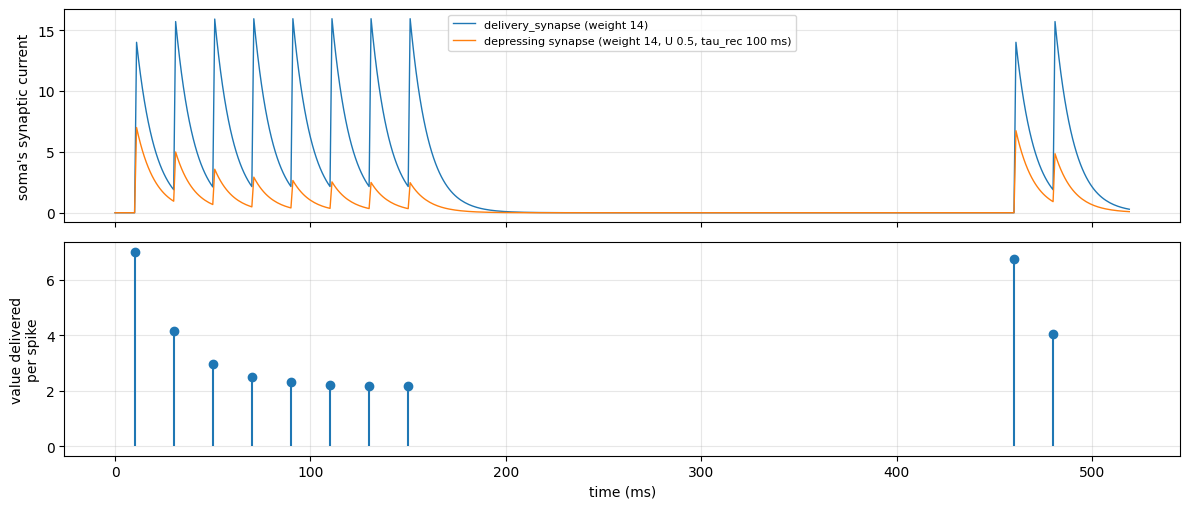

In [3]:
TRAIN = list(range(10, 160, 20)) + [460, 480]    # eight spikes at 50 Hz, a 300 ms pause, two more
TICKS = 520


def depression_run(stepping):
    model = new_model(stepping)
    model.register_synapse_type(
        name="user_customized_depressing_synapse",
        step_func=user_customized_depressing_synapse,
        step_func_path=STEP_FUNC_DIR / "user_customized_depressing_synapse.py",
        event_capable=True,       # only needs to run on the tick after a spike
    )
    plain = model.create_soma(breed="lif_soma", config_name="config_0", overrides={"hyperparameters": NO_SPIKES})
    depressed = model.create_soma(breed="lif_soma", config_name="config_0", overrides={"hyperparameters": NO_SPIKES})
    syn_plain = model.create_synapse(breed="delivery_synapse", pre_soma_id=-1, post_soma_id=plain,
                                     config_name="config_0")                 # weight 14, channel 0
    syn_dep = model.create_synapse(breed="user_customized_depressing_synapse", pre_soma_id=-1,
                                   post_soma_id=depressed, config_name="config_0")   # weight 14, U 0.5, tau_rec 100 ms
    model.setup()
    for tick in TRAIN:
        model.add_spike(syn_plain, tick, 1.0)
        model.add_spike(syn_dep, tick, 1.0)
    model.simulate(ticks=TICKS)
    return (history(model, plain)[:, 3], history(model, depressed)[:, 3],
            model.get_hyperparameters(syn_dep))


I_plain, I_dep, dep_hp = depression_run("event")
_, I_dep_clocked, _ = depression_run("clocked")

# The value delivered on each spike, read back from the soma's current: I[t+1] - I[t] * (1 - dt/tau_syn_0)
f = 1 - DT / 10e-3
delivered = lambda I: np.array([I[t + 1] - I[t] * f for t in TRAIN])
# The closed form of the model
U, tau_rec, w = dep_hp["U"], dep_hp["tau_rec"], dep_hp["weight"]
x, last, expected = 1.0, None, []
for tick in TRAIN:
    if last is not None:
        x = 1 - (1 - x) * (1 - DT / tau_rec) ** (tick - last)
    expected.append(w * U * x)
    x, last = x - U * x, tick

print("delivered by delivery_synapse:  ", np.round(delivered(I_plain), 3))
print("delivered by the depressing one:", np.round(delivered(I_dep), 3))
print("closed form:                    ", np.round(expected, 3))
print("event and clocked stepping give the same current, bit for bit:", np.array_equal(I_dep, I_dep_clocked))

fig, axes = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True)
t_ms = np.arange(TICKS) * DT * 1e3
axes[0].plot(t_ms, I_plain, lw=1, label="delivery_synapse (weight 14)")
axes[0].plot(t_ms, I_dep, lw=1, label="depressing synapse (weight 14, U 0.5, tau_rec 100 ms)")
axes[0].set_ylabel("soma's synaptic current")
axes[0].legend(fontsize=8)
axes[1].stem(np.array(TRAIN) * DT * 1e3, delivered(I_dep), basefmt=" ")
axes[1].set_ylabel("value delivered\nper spike")
axes[1].set_xlabel("time (ms)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The plain synapse delivers 14 on every spike. The depressing one delivers `14 * 0.5 = 7` on the
first, then less on each spike of the 50 Hz train as its resources run down, and after the
300 ms pause it is almost back to 7. The values match the closed form, and the soma's current is
the same whether the synapse is stepped only when woken or on every tick.

Other things a synapse step function can decide, all at the moment of the spike: the sign or a
nonlinear function of the weight, a random draw (device noise), a value that depends on the post
soma's state at that moment, or deliveries into several channels (tutorial 02's
double-exponential synapse delivers `+w` into one channel and `-w` into another). What it cannot
change is what happens to the value after it is delivered: that is the soma's channel decay.

## 3. Changing what the soma does with its channels: a soma step function

The soma runs on every tick, so it decides what the delivered input does over time. The built-in
somas gather each channel, decay it, and add the channels up as a **current**. A soma step
function can use the channels differently. The example, `user_customized_conductance_lif.py`,
treats each channel as a **conductance** with its own reversal potential:

```python
g_0 = g_0 * (1 - dt / tau_syn_0) + read_synaptic_input(agent_index, synaptic_input, synaptic_input_idx, 0)
g_1 = g_1 * (1 - dt / tau_syn_1) + read_synaptic_input(agent_index, synaptic_input, synaptic_input_idx, 1)
I = g_0 * (E_rev_0 - v) + g_1 * (E_rev_1 - v)      # instead of I = I_syn_0 + I_syn_1
```

The gather-and-decay part is the same (`read_synaptic_input` reads one channel of the inbox);
the membrane update after it is the built-in `lif_soma`'s. What changes is that the effect of an
input now depends on the membrane potential `v` on every tick, through the driving force
`E_rev - v`. A synapse could not do this in event mode, because it runs only on the tick after a
spike; the soma runs every tick, so it is the place for it.

The synapses stay the built-in `delivery_synapse`. Channel 1 has `E_rev_1 = -80 mV`, so an
inhibitory synapse here has a *positive* weight and gets its sign from `E_rev_1 - v`. In
`lif_soma`, where the channel is a current, inhibition is a negative weight instead.

The cell gives one inhibitory spike to each kind of soma at two membrane levels: at rest
(-60 mV) and held at -50 mV by a constant input current `I_in`.

soma                                       level               IPSP (mV)
lif_soma (channel = current)               at rest (-60 mV)        -7.75
lif_soma (channel = current)               held at -50 mV          -7.75
conductance soma (channel = conductance)   at rest (-60 mV)        -6.10
conductance soma (channel = conductance)   held at -50 mV          -9.15


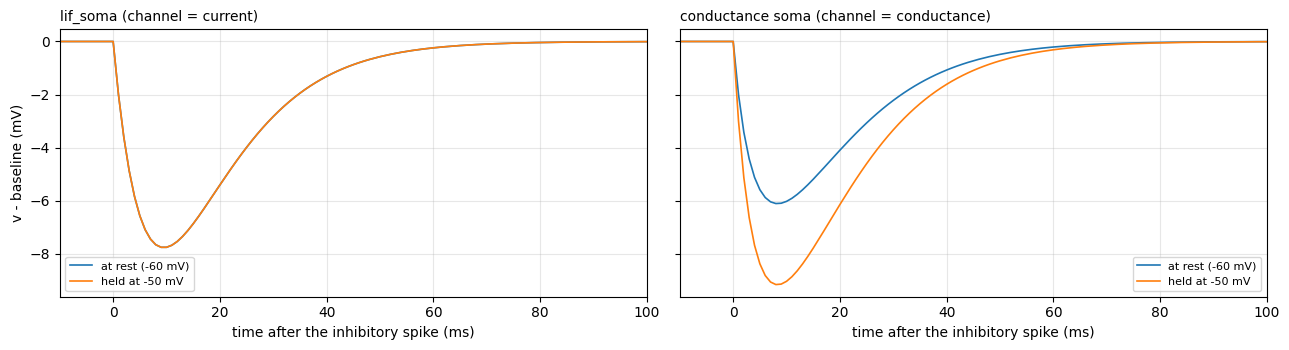

In [4]:
TICKS, SPIKE = 300, 150        # the membrane settles first, then one inhibitory spike at tick 150

model = new_model()
model.register_soma_type(
    name="user_customized_conductance_lif",
    step_func=user_customized_conductance_lif,
    step_func_path=STEP_FUNC_DIR / "user_customized_conductance_lif.py",
)
LEVELS = {"at rest (-60 mV)": 0.0, "held at -50 mV": 1e-5}     # I_in: R * I_in = +10 mV
KINDS = {   # soma breed -> the inhibitory synapse's hyperparameters
    "lif_soma (channel = current)": ("lif_soma", {"weight": -2.0, "channel": 0}),
    "conductance soma (channel = conductance)": ("user_customized_conductance_lif", {"weight": 0.1, "channel": 1}),
}
cases = {}
for kind, (breed, syn_hp) in KINDS.items():
    for level, I_in in LEVELS.items():
        soma = model.create_soma(breed=breed, config_name="config_0",
                                 overrides={"hyperparameters": {**NO_SPIKES, "I_in": I_in}})
        syn = model.create_synapse(breed="delivery_synapse", pre_soma_id=-1, post_soma_id=soma,
                                   config_name="config_0", overrides={"hyperparameters": syn_hp})
        cases[(kind, level)] = (soma, syn)
model.setup()
for soma, syn in cases.values():
    model.add_spike(syn, SPIKE, 1.0)
model.simulate(ticks=TICKS)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
t_ms = (np.arange(TICKS) - SPIKE) * DT * 1e3
print(f"{'soma':42s} {'level':18s} {'IPSP (mV)':>10s}")
for ax, kind in zip(axes, KINDS):
    for level in LEVELS:
        v = history(model, cases[(kind, level)][0])[:, 0]
        baseline = v[SPIKE - 1]
        print(f"{kind:42s} {level:18s} {v[SPIKE:].min() - baseline:+10.2f}")
        ax.plot(t_ms, v - baseline, lw=1.2, label=level)
    ax.set_title(kind, loc="left", fontsize=10)
    ax.set_xlim(-10, 100)
    ax.set_xlabel("time after the inhibitory spike (ms)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("v - baseline (mV)")
plt.tight_layout()
plt.show()

In `lif_soma` the inhibitory input is a current, and the same spike moves the membrane by the
same amount at both levels. In the conductance soma it is a conductance, and the same spike moves
the membrane more at -50 mV than at rest, because the driving force `E_rev_1 - v` is -30 mV there
against -20 mV at rest; it also flattens as `v` approaches -80 mV. The synapse delivered the same
value in both cases; the soma decided what it means.

The full-size version of this soma is tutorial 04's `user_customized_diehl_cook_soma.py`: an
excitatory and an inhibitory conductance channel with their own time constants, plus an adaptive
threshold.

## 4. Which step function to write

| you want | write | example | stepping |
|---|---|---|---|
| a different value per spike: depression or facilitation, noise, a function of the weight, delivery into several channels | a **synapse** step function that computes the value and calls `deliver_synaptic_current`; register with `register_synapse_type(..., event_capable=True)` | `user_customized_depressing_synapse.py` (this tutorial), `user_customized_double_exp_synapse.py` (tutorial 02) | event |
| a different use of the channels: conductances, a different filter, a voltage dependence | a **soma** step function that reads its inbox (`read_synaptic_input`, or `synaptic_current` for the standard filter); register with `register_soma_type` | `user_customized_conductance_lif.py` (this tutorial), `user_customized_diehl_cook_soma.py` (tutorial 04) | either |
| a synapse that acts on every tick, not only after a spike (gap junction, a current of its own per synapse) | a synapse step function that delivers every tick, registered without `event_capable` | `user_customized_gap_junction.py` (tutorial 05, section 5) | clocked, for the whole model |

In every case the synapse still ends with a delivery into a channel, and the soma still reads its
inbox: those two are the whole interface between them. The kernel signatures and the YAML layout
are in `docs/CUSTOM_COMPONENTS.md`; tutorial 05 explains event and clocked stepping and how to
check a custom component in both.